# Bolsas do ProUni no Brasil (2005–2019)

**Wikten Alves · Unilasalle-RJ · Sistemas de Informação**  
**Linguagem de Programação (Análise e Visualização de Dados com Python) · 6º período · 2026.2**

Este notebook explora a [versão 1 da distribuição do Kaggle](https://www.kaggle.com/datasets/lfarhat/brasil-students-scholarship-prouni-20052019), compilada por Leo Farhat a partir do tema de dados abertos do MEC. Cada contagem representa registros de bolsas. O ETL é executado com `python -m src.etl` na raiz do projeto; este notebook lê as saídas agregadas.

1. **RQ1** · Como evoluiu o total anual de bolsas?
2. **RQ2** · Como os registros se distribuíram por região e UF?
3. **RQ3** · Como variou a participação da EaD?

In [1]:
import sys
from io import BytesIO
from pathlib import Path

raiz = next(
    (pasta for pasta in (Path.cwd(), *Path.cwd().parents)
     if (pasta / "src" / "etl.py").is_file()),
    None,
)
if raiz is None:
    raise FileNotFoundError("Abra a pasta do projeto no JupyterLab.")
sys.path.insert(0, str(raiz))

from IPython.display import Image, display
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from src.analise import analisar, carregar_dados
from src.publicar import grafico_ranking, pt

def mostrar_figura(figura):
    imagem = BytesIO()
    figura.savefig(imagem, format="png", dpi=120, bbox_inches="tight")
    plt.close(figura)
    display(Image(data=imagem.getvalue()))

dados, qualidade = carregar_dados()
anual, tipos, estados, regioes, metricas = analisar(dados)
dados.head()

,ano,uf,regiao,modalidade,tipo_bolsa,bolsas
0,2005,AC,Norte,EaD,Integral,2
1,2005,AC,Norte,Presencial,Integral,61
2,2005,AC,Norte,Presencial,Parcial 50%,60
3,2005,AL,Nordeste,EaD,Integral,3
4,2005,AL,Nordeste,Presencial,Integral,159


## Validação da tabela processada

A soma de `bolsas` deve coincidir com o número de registros de origem. Cada combinação das cinco dimensões deve aparecer uma única vez. As linhas sem UF entram no total nacional, e apenas as linhas com UF identificada entram nos percentuais geográficos.

In [2]:
dimensoes = ["ano", "uf", "regiao", "modalidade", "tipo_bolsa"]
assert dados["bolsas"].sum() == qualidade["linhas_lidas"]
assert dados["bolsas"].gt(0).all()
assert not dados.duplicated(dimensoes).any()
assert list(anual.index) == list(range(2005, 2020))
assert dados.loc[dados["uf"] == "NI", "bolsas"].sum() == qualidade["ausentes_uf"]
assert (anual["ead"] + anual["presencial"]).equals(anual["total"])
qualidade

{'dataset': 'lfarhat/brasil-students-scholarship-prouni-20052019',
 'versao': 1,
 'csv_sha256': '397fb45ec457e3e02d7cf4f1e59bfbd4bd6b9d0bc17e41f6eac640fc78da2540',
 'linhas_lidas': 2692540,
 'ausentes_ano': 0,
 'ausentes_tipo_bolsa': 0,
 'ausentes_modalidade': 0,
 'ausentes_regiao_origem': 402,
 'ausentes_uf': 402,
 'regioes_declaradas_divergentes': 0,
 'bolsas_processadas': 2692540,
 'grupos_processados': 1629}

## RQ1 · Evolução anual

A série usa uma contagem por ano. A coluna de variação anual compara cada total com o ano anterior. O primeiro ano fica vazio por não ter ano anterior na base.

In [3]:
display(anual[["total", "variacao_pct"]].round(2))
display(tipos)

,total,variacao_pct
ano,,
2005,95629,NaN
2006,109025,14.01
2007,105574,-3.17
2008,124621,18.04
2009,161369,29.49
2010,152733,-5.35
2011,170766,11.81
2012,176764,3.51
2013,177326,0.32


tipo_bolsa,Complementar 25%,Integral,Parcial 50%
ano,,,
2005,0,67276,28353
2006,0,86141,22884
2007,0,73561,32013
2008,2330,76643,45648
2009,0,113647,47722
2010,0,96216,56517
2011,0,106516,64250
2012,0,119191,57573
2013,0,134571,42755


pico_ano 2015
pico 252650
mediana 176764.0
q1 138677.0
q3 231095.5
iqr 92418.5
anos_atipicos []


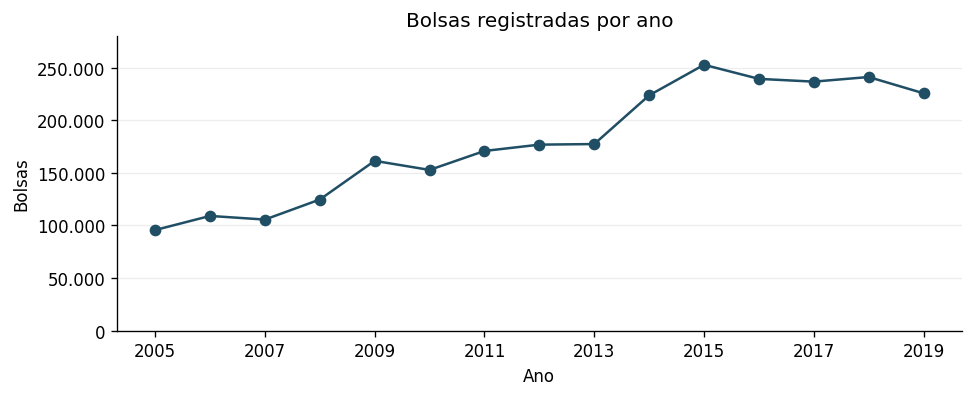

In [4]:
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
ax.plot(anual.index, anual["total"], marker="o", color="#204e65")
ax.set(title="Bolsas registradas por ano", xlabel="Ano", ylabel="Bolsas",
       ylim=(0, 280_000), xticks=range(2005, 2020, 2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: pt(valor)))
ax.grid(axis="y", alpha=.22)
mostrar_figura(fig)

for chave in ("pico_ano", "pico", "mediana", "q1", "q3", "iqr", "anos_atipicos"):
    print(chave, metricas[chave])

O pico foi de **252.650** registros em 2015. O total em 2019 foi 135,86% maior que em 2005. Nenhum ano ultrapassou as cercas de 1,5 × IQR. O critério identifica valores muito afastados da distribuição, com sensibilidade limitada a mudanças graduais na série.

## RQ2 · Distribuição geográfica

Divida o volume de cada região ou UF pelo número de registros com UF conhecida. A UF de referência vem do campo do beneficiário. A distribuição mede contagens absolutas de concessões.

,bolsas,participacao_pct
regiao,,
Sudeste,1289321,47.89
Sul,491560,18.26
Nordeste,486819,18.08
Centro-Oeste,247089,9.18
Norte,177349,6.59


,uf,regiao,bolsas,participacao_pct
0,SP,Sudeste,761375,28.28
1,MG,Sudeste,326924,12.14
2,RS,Sul,206886,7.68
3,PR,Sul,196098,7.28
4,BA,Nordeste,158218,5.88
5,RJ,Sudeste,152339,5.66
6,GO,Centro-Oeste,90779,3.37
7,SC,Sul,88576,3.29
8,PE,Nordeste,73834,2.74
9,DF,Centro-Oeste,72583,2.70


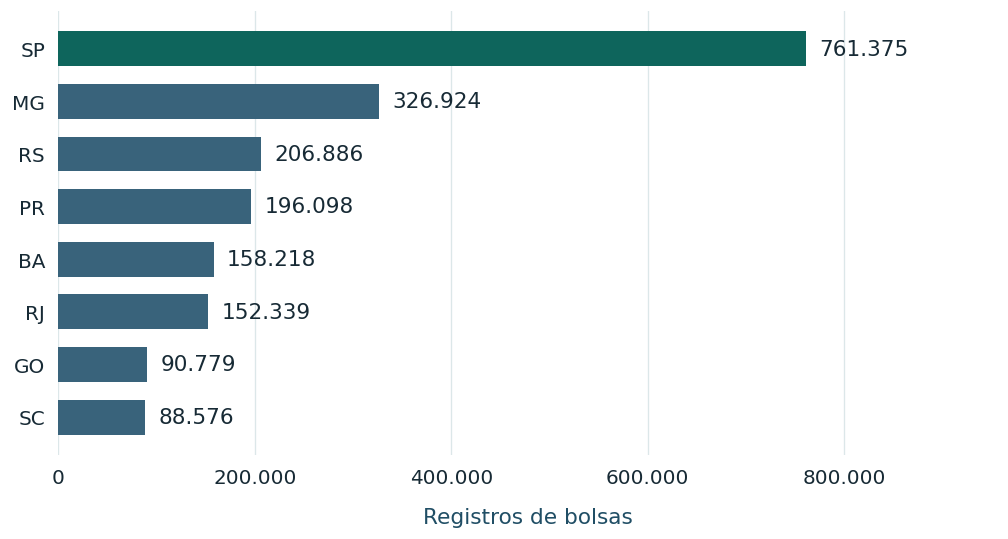

In [5]:
display(regioes.round(2))
display(estados.head(10).round(2))
mostrar_figura(grafico_ranking(estados))

O Sudeste reuniu **47,89%** dos registros com UF. São Paulo, Minas Gerais e Rio Grande do Sul somaram **48,11%**. Para comparar cobertura entre UFs, seria necessário um denominador comparável, como o total de pessoas elegíveis.

## RQ3 · Participação anual da EaD

A fração anual divide o número de registros EaD pelo total do ano. O percentual acumulado usa as somas do período. A correlação de Spearman descreve a associação entre a ordem dos anos e a ordem das participações anuais.

Variação (pontos percentuais): 24,83
Participação acumulada: 18,59%
Spearman: 0,943


,ead,presencial,ead_pct
ano,,,
2005,4768,90861,4.99
2006,6256,102769,5.74
2007,11190,94384,10.60
2008,13910,110711,11.16
2009,24816,136553,15.38
2010,21267,131466,13.92
2011,25127,145639,14.71
2012,32665,144099,18.48
2013,40625,136701,22.91


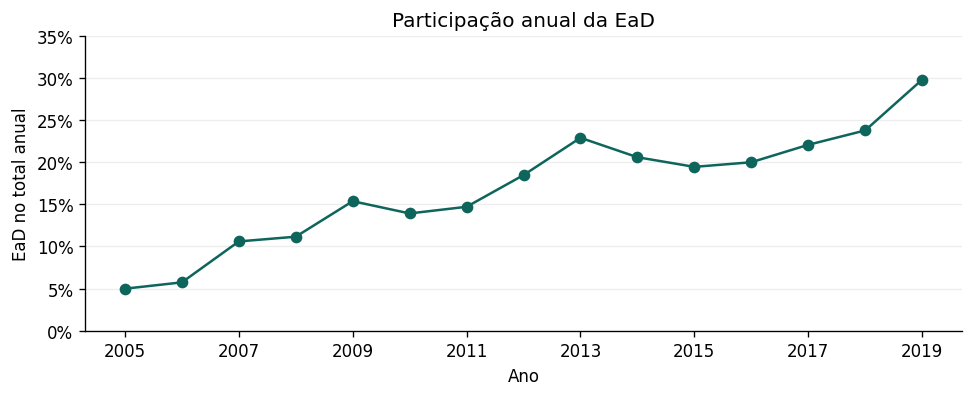

In [6]:
display(anual[["ead", "presencial", "ead_pct"]].round(2))
fig, ax = plt.subplots(figsize=(8, 3.2), layout="constrained")
ax.plot(anual.index, anual["ead_pct"], marker="o", color="#0e655c")
ax.set(title="Participação anual da EaD", xlabel="Ano", ylabel="EaD no total anual",
       ylim=(0, 35), xticks=range(2005, 2020, 2))
ax.yaxis.set_major_formatter(FuncFormatter(lambda valor, _: pt(valor) + "%"))
ax.grid(axis="y", alpha=.22)
mostrar_figura(fig)

print("Variação (pontos percentuais):", pt(metricas["ead_aumento_pp"], 2))
print("Participação acumulada:", pt(metricas["ead_pct"], 2) + "%")
print("Spearman:", pt(metricas["spearman"], 3))

A participação da EaD cresceu **24,83 pontos percentuais** (4,99% para 29,82%). Em 2019 subiu o volume EaD e caiu o volume presencial em relação a 2018. A associação observada não estima efeito causal nem demanda pela modalidade.

## Limitações

A base representa registros de concessões desta distribuição. Não é possível contar beneficiários únicos com segurança. As conclusões também não medem permanência, conclusão de curso ou cobertura da população elegível. O artigo é gerado com `python -m src.publicar` a partir da mesma rotina analítica.